# 🎬 TMDB Movies: Анализ эффективности и финансовых метрик киноиндустрии

## 📌 Бизнес-контекст и цели проекта
Как продуктовый аналитик гипотетического стримингового сервиса, я исследую датасет **TMDB 5000 Movies**, чтобы ответить на ключевые вопросы развития контентной сетки:
1. **Финансовая эффективность:** Что выгоднее для сервиса — блокбастеры с высокими бюджетами или нишевое кино с максимальным ROI (коэффициентом окупаемости)?
2. **Жанровый разрез:** Какие жанры показывают лучшую отдачу на вложенный доллар?
3. **Динамика хронометража:** Как менялась медианная продолжительность фильмов с 1970 по 2016 годы и к какому стандарту пришли релизы?

---
### 🛠 Стек технологий:
`Python`, `Pandas`, `NumPy`, `Matplotlib`, `VS Code / Jupyter Notebook`

In [7]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

# Настройка стилей графиков
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Загрузка датасета
movies = pd.read_csv('tmdb_5000_movies.csv')

# Быстрая проверка размера
print(f"Загружено записей: {movies.shape[0]}, Колонок: {movies.shape[1]}")
movies.head(3)

Загружено записей: 4803, Колонок: 20


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466


## 1. Предобработка данных и очистка JSON
Колонка `genres` содержит данные в формате JSON-строк. Выделим из них список жанров и определим **главный (основной) жанр** для каждого фильма, а также отфильтруем невалидные финансовые записи.

In [8]:
# Функция для парсинга JSON-строки с жанрами
def extract_genres(json_str):
    try:
        genres_list = json.loads(json_str)
        return [g['name'] for g in genres_list]
    except:
        return []

# Парсим жанры и выделяем главный жанр
movies['genres_list'] = movies['genres'].apply(extract_genres)
movies['main_genre'] = movies['genres_list'].apply(lambda x: x[0] if len(x) > 0 else 'Unknown')

# Фильтруем данные: оставляем записи с валидными бюджетом и выручкой (> $1,000)
financial_movies = movies[(movies['budget'] > 1000) & (movies['revenue'] > 1000)].copy()

# Расчет ключевых метрик
financial_movies['net_profit'] = financial_movies['revenue'] - financial_movies['budget']
financial_movies['roi'] = financial_movies['revenue'] / financial_movies['budget']

print(f"Отфильтровано корректных финансовых записей: {len(financial_movies)}")

Отфильтровано корректных финансовых записей: 3211


## 2. Финансовые метрики: Net Profit vs ROI
Сравним самые кассовые фильмы с точки зрения чистой прибыли и с точки зрения коэффициента окупаемости (ROI).

In [9]:
print("=== ТОП-5 ФИЛЬМОВ ПО ЧИСТОЙ ПРИБЫЛИ (Net Profit) ===")
display(financial_movies[['title', 'budget', 'revenue', 'net_profit', 'roi']]
        .sort_values(by='net_profit', ascending=False)
        .head(5))

print("\n=== ТОП-5 САМЫХ ОКУПАЕМЫХ ФИЛЬМОВ (ROI от $100k) ===")
display(financial_movies[financial_movies['budget'] > 100000][['title', 'budget', 'revenue', 'net_profit', 'roi']]
        .sort_values(by='roi', ascending=False)
        .head(5))

=== ТОП-5 ФИЛЬМОВ ПО ЧИСТОЙ ПРИБЫЛИ (Net Profit) ===


,title,budget,revenue,net_profit,roi
0,Avatar,237000000,2787965087,2550965087,11.763566
25,Titanic,200000000,1845034188,1645034188,9.225171
28,Jurassic World,150000000,1513528810,1363528810,10.090192
44,Furious 7,190000000,1506249360,1316249360,7.927628
16,The Avengers,220000000,1519557910,1299557910,6.907081



=== ТОП-5 САМЫХ ОКУПАЕМЫХ ФИЛЬМОВ (ROI от $100k) ===


,title,budget,revenue,net_profit,roi
4514,Open Water,130000,54667954,54537954,420.522723
4441,Bambi,858000,267447150,266589150,311.709965
3737,Night of the Living Dead,114000,30000000,29886000,263.157895
4670,Mad Max,400000,100000000,99600000,250.000000
2409,Halloween,300000,70000000,69700000,233.333333


> 💡 **Вывод:** Блокбастеры (*Avatar*, *Titanic*) генерируют большую чистую прибыль ($1.2B–$2.5B), но требуют гигантских инвестиций ($150M+). В то же время малобюджетные релизы (*Open Water*, *Mad Max*) демонстрируют колоссальный ROI (**200x–400x**), подтверждая эффективность нишевого кино.


## 3. Анализ маржинальности по жанрам
Сгруппируем фильмы по главному жанру и посчитаем медианный ROI (используем медиану для защиты от искажений аномальными выбросами).

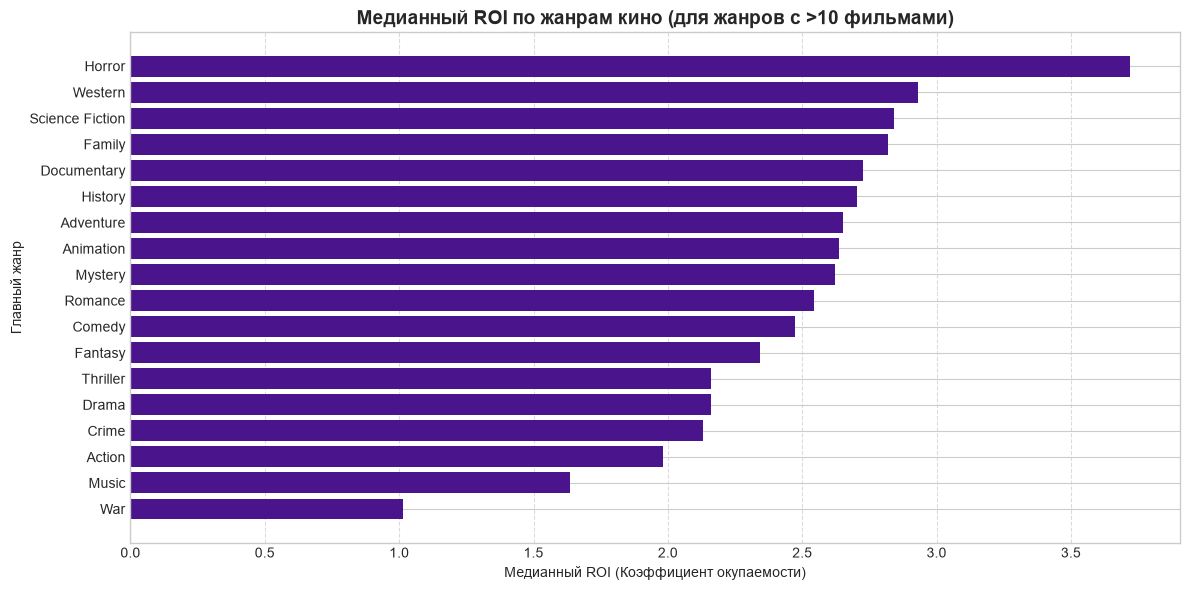

In [10]:
# Группировка по жанрам
genre_stats = financial_movies.groupby('main_genre').agg(
    count=('title', 'count'),
    median_budget=('budget', 'median'),
    median_roi=('roi', 'median')
).reset_index()

# Фильтруем репрезентативные жанры (>10 фильмов)
genre_stats = genre_stats[genre_stats['count'] >= 10].sort_values(by='median_roi', ascending=True)

# Визуализация
plt.figure(figsize=(12, 6))
plt.barh(genre_stats['main_genre'], genre_stats['median_roi'], color='#4a148c')
plt.title('Медианный ROI по жанрам кино (для жанров с >10 фильмами)', fontsize=14, fontweight='bold')
plt.xlabel('Медианный ROI (Коэффициент окупаемости)')
plt.ylabel('Главный жанр')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> 💡 **Вывод:** **Ужасы (Horror)** являют собой наиболее окупаемый жанр с медианным ROI **3.7x** при скромных бюджетах (медиана ~$6.1M). Жанры вроде *Adventure* или *Animation* требуют бюджета $60M–$80M, при этом показывают меньший медианный ROI (~2.6x).

## 4. Эволюция продолжительности фильмов (1970–2016 гг.)
Оценим, как менялся хронометраж кинолент за последние 45 лет.

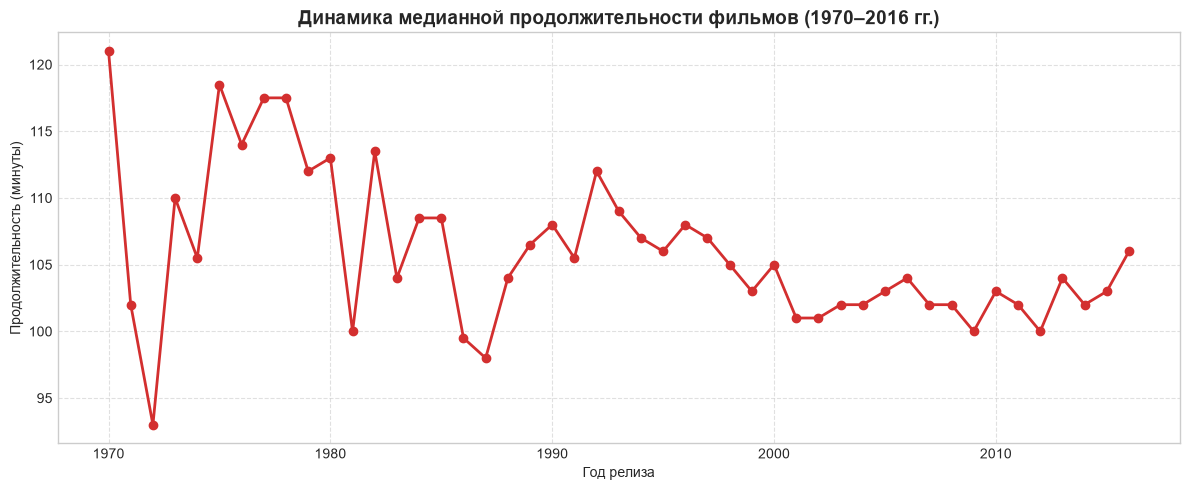

In [11]:
movies['release_year'] = pd.to_datetime(movies['release_date'], errors='coerce').dt.year
yearly_movies = movies[(movies['release_year'] >= 1970) & (movies['release_year'] <= 2016)].copy()

yearly_stats = yearly_movies.groupby('release_year').agg(
    median_runtime=('runtime', 'median')
).reset_index()

plt.figure(figsize=(12, 5))
plt.plot(yearly_stats['release_year'], yearly_stats['median_runtime'], marker='o', color='#d32f2f', linewidth=2)
plt.title('Динамика медианной продолжительности фильмов (1970–2016 гг.)', fontsize=14, fontweight='bold')
plt.xlabel('Год релиза')
plt.ylabel('Продолжительность (минуты)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 🏁 Итоговое резюме исследования

1. **Стратегия закупки контента:** Для минимизации рисков платформе выгодно инвестировать в категорию Originals в жанре **Horror** — это дает высокий возвращаемый ROI на каждый вложенный доллар.
2. **Формат контента:** С середины 2000-х годов хронометраж фильмов стабилизировался в диапазоне **100–105 минут**, что следует учитывать при формировании сетки вещания и планировании пользовательских сессий.